In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
#passive_data = pd.read_csv('/Users/eochoa/Downloads/MPConc_WeatherMonthLocation_Passive.csv')
passive_data = pd.read_csv('evaluation_data/MPConc_WeatherMonthLocation_Passive_UPDATED.csv')
passive_data.head()

,School,Month,Conc MP (%),Conc TWP (%),Avg temperature (F),Avg dew point (F),Avg humidity (%),Avg wind speed (mph),Avg total precipitation (in)
0,FHS,Mar,0.000000,0.001139,38.817241,31.006897,75.620690,1.451724,0.074483
1,FHS,Apr,0.000000,0.007234,51.634483,40.344828,68.241379,6.162069,0.094828
2,FHS,May,0.000000,0.004479,62.853571,53.921429,75.321429,3.253571,0.098571
3,FHS,Jun,0.013514,0.009824,68.306667,60.066667,77.233333,3.150000,0.141333
4,FHS,Jul,0.000000,0.001323,70.017857,63.867857,82.321429,2.035714,0.220000


In [3]:
#passive_data = pd.read_csv('/Users/eochoa/Downloads/MPConc_WeatherMonthLocation_Passive.csv')
passive_data = pd.read_csv('evaluation_data/MPConc_WeatherMonthLocation_Passive_UPDATED.csv')
passive_data.head()

,School,Month,Conc MP (%),Conc TWP (%),Avg temperature (F),Avg dew point (F),Avg humidity (%),Avg wind speed (mph),Avg total precipitation (in)
0,FHS,Mar,0.000000,0.001139,38.817241,31.006897,75.620690,1.451724,0.074483
1,FHS,Apr,0.000000,0.007234,51.634483,40.344828,68.241379,6.162069,0.094828
2,FHS,May,0.000000,0.004479,62.853571,53.921429,75.321429,3.253571,0.098571
3,FHS,Jun,0.013514,0.009824,68.306667,60.066667,77.233333,3.150000,0.141333
4,FHS,Jul,0.000000,0.001323,70.017857,63.867857,82.321429,2.035714,0.220000


In [3]:
passive_data.columns

Index(['School', 'Month', 'Conc MP (%)', 'Conc TWP (%)', 'Avg temperature (F)',
       'Avg dew point (F)', 'Avg humidity (%)', 'Avg wind speed (mph)',
       'Avg total precipitation (in)'],
      dtype='object')

In [4]:
passive_data.columns

Index(['School', 'Month', 'Conc MP (%)', 'Conc TWP (%)', 'Avg temperature (F)',
       'Avg dew point (F)', 'Avg humidity (%)', 'Avg wind speed (mph)',
       'Avg total precipitation (in)'],
      dtype='object')

In [5]:
X_cat = pd.get_dummies(
    passive_data.loc[:, ['School', 'Month']],
    drop_first=True
)

X = passive_data.loc[:, ['Avg temperature (F)',
       'Avg dew point (F)', 'Avg humidity (%)', 'Avg wind speed (mph)',
       'Avg total precipitation (in)']]
X = sm.add_constant(X)  # adds intercept

X = pd.concat([X_cat, X], axis=1)
y = passive_data["Conc MP (%)"]*1000

model = sm.OLS(y, X).fit()

In [6]:
num_vars = ['Avg temperature (F)',
       'Avg dew point (F)', 'Avg humidity (%)', 'Avg wind speed (mph)',
       'Avg total precipitation (in)']
cat_vars = ['School', 'Month']

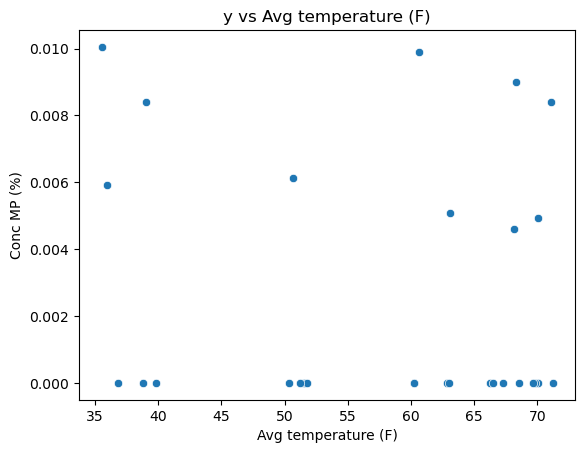

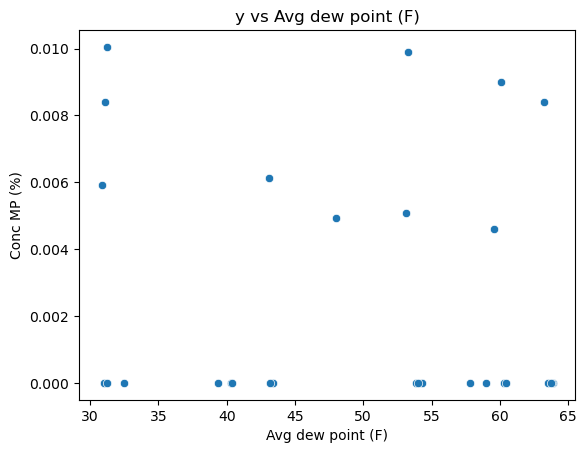

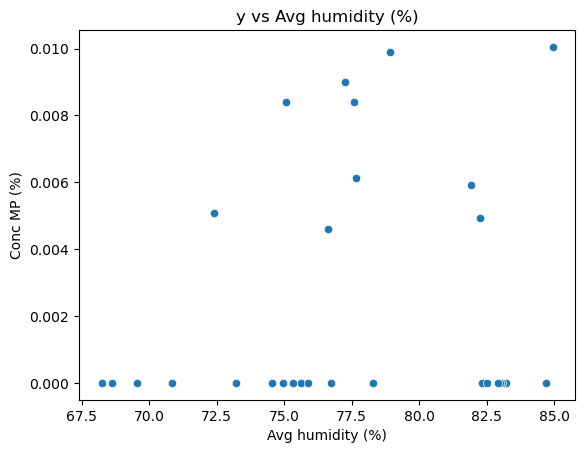

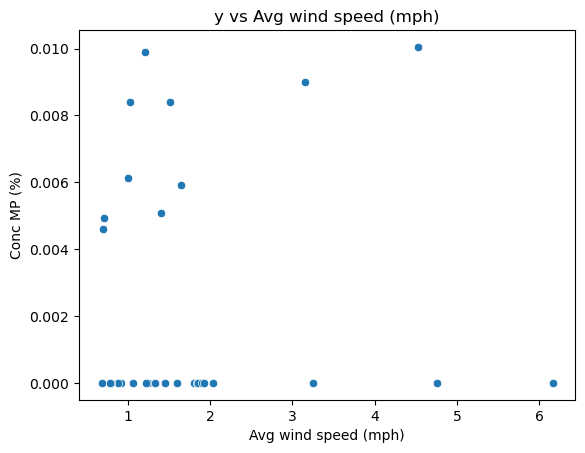

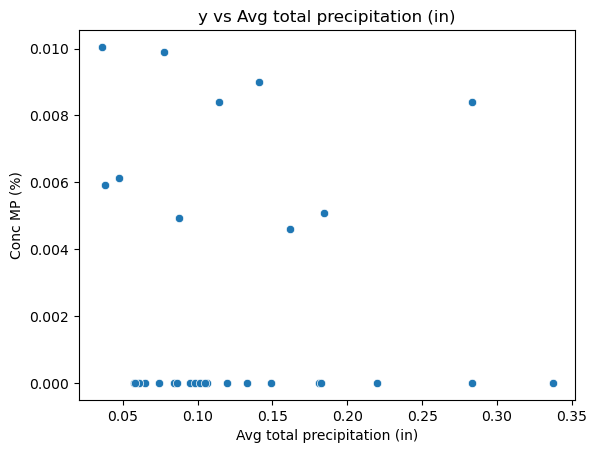

In [6]:
for col in num_vars:
    if col != 'Conc MP (%)':
        plt.figure()
        sns.scatterplot(x=passive_data[col], y=passive_data['Conc MP (%)'])
        plt.title(f"y vs {col}")
        plt.show()

In [7]:
passive_data.groupby('School').mean()['Conc MP (%)']

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_4897/2980377753.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  passive_data.groupby('School').mean()['Conc MP (%)']


School
DC     0.002407
FHS    0.001906
IAO    0.002930
Name: Conc MP (%), dtype: float64

In [8]:
passive_data.groupby('Month').mean()['Conc MP (%)']

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_4897/645331718.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  passive_data.groupby('Month').mean()['Conc MP (%)']


Month
Apr    0.000000
Aug    0.001642
Dec    0.005322
Jul    0.002801
Jun    0.004539
Mar    0.002801
May    0.001692
Nov    0.002045
Oct    0.003300
Sep    0.000000
Name: Conc MP (%), dtype: float64

,Conc MP (%),Avg temperature (F),Avg dew point (F),Avg humidity (%),Avg wind speed (mph),Avg total precipitation (in)
0,0.000000,38.817241,31.006897,75.620690,1.451724,0.074483
1,0.000000,51.634483,40.344828,68.241379,6.162069,0.094828
2,0.000000,62.853571,53.921429,75.321429,3.253571,0.098571
3,0.009009,68.306667,60.066667,77.233333,3.150000,0.141333
4,0.000000,70.017857,63.867857,82.321429,2.035714,0.220000
5,0.000000,69.837500,63.845833,83.041667,1.804167,0.106250
6,0.000000,66.263636,60.306061,83.212121,1.836364,0.119697
7,0.000000,60.269231,54.303846,83.076923,1.853846,0.065000
8,0.000000,51.576667,43.386667,75.866667,4.756667,0.057667
9,0.010050,35.534375,31.262500,84.937500,4.531250,0.035937


In [9]:
np.corrcoef(np.array(X).T)

/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


array([[ 1.00000000e+00, -5.00000000e-01, -9.81307787e-18,
         2.61682076e-17, -9.81307787e-18, -9.81307787e-18,
         3.27102596e-18, -1.63551298e-17,  1.47196168e-17,
         3.27102596e-18, -3.27102596e-18,             nan,
        -9.65817400e-03,  4.66852443e-02,  1.72464634e-01,
         6.95980077e-01, -2.30167730e-01],
       [-5.00000000e-01,  1.00000000e+00, -3.27102596e-18,
         2.61682076e-17, -3.27102596e-18, -3.27102596e-18,
         1.63551298e-17, -9.81307787e-18,  1.47196168e-17,
         9.81307787e-18,  3.27102596e-18,             nan,
         1.76876103e-02,  3.70293567e-04, -3.50909746e-01,
        -2.44946600e-01,  1.16458665e-01],
       [-9.81307787e-18, -3.27102596e-18,  1.00000000e+00,
        -1.11111111e-01, -1.11111111e-01, -1.11111111e-01,
        -1.11111111e-01, -1.11111111e-01, -1.11111111e-01,
        -1.11111111e-01, -1.11111111e-01,             nan,
         3.52388291e-01,  2.56961712e-01,  2.39978021e-01,
        -1.72883443e-01,  1.4

<AxesSubplot: >

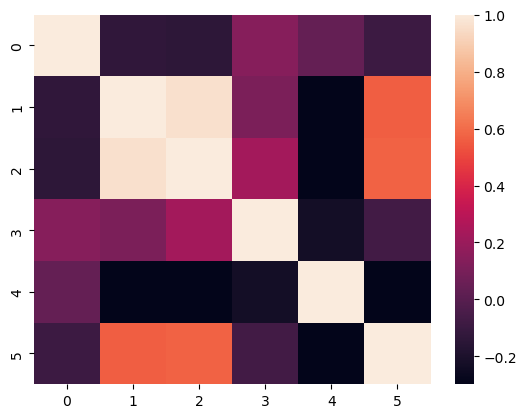

In [10]:
X = passive_data.loc[:, ['Conc MP (%)', 'Avg temperature (F)',
       'Avg dew point (F)', 'Avg humidity (%)', 'Avg wind speed (mph)',
       'Avg total precipitation (in)']]
sns.heatmap(np.corrcoef(np.array(X).T))

(array([20.,  0.,  0.,  0.,  2.,  2.,  1.,  0.,  3.,  2.]),
 array([ 0.       ,  1.0050251,  2.0100502,  3.0150753,  4.0201004,
         5.0251255,  6.0301506,  7.0351757,  8.0402008,  9.0452259,
        10.050251 ]),
 <BarContainer object of 10 artists>)

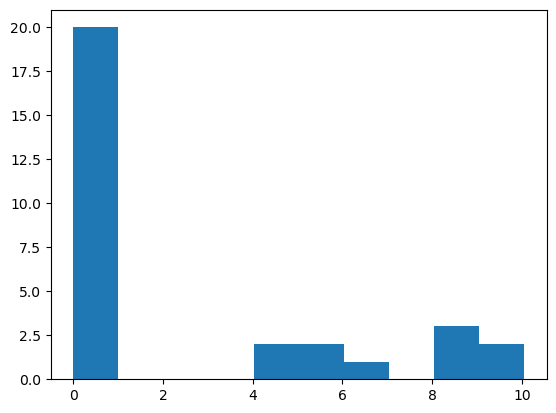

In [11]:
plt.hist(y)

In [12]:
f_test = model.f_test("School_FHS = 0, School_IAO = 0")
f_test

<class 'statsmodels.stats.contrast.ContrastResults'>
<F test: F=0.35989228344618285, p=0.7044892851997044, df_denom=13, df_num=2>

In [13]:
f_test = model.f_test('Month_Aug=0, Month_Dec=0, Month_Jul=0, Month_Jun=0, Month_Mar=0, Month_May=0, Month_Nov=0, Month_Oct=0, Month_Sep=0')
f_test

<class 'statsmodels.stats.contrast.ContrastResults'>
<F test: F=0.5960029171697587, p=0.7794800954711976, df_denom=13, df_num=9>

In [14]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            Conc MP (%)   R-squared:                       0.388
Model:                            OLS   Adj. R-squared:                 -0.365
Method:                 Least Squares   F-statistic:                    0.5151
Date:                Sat, 03 Jan 2026   Prob (F-statistic):              0.895
Time:                        23:34:01   Log-Likelihood:                -73.696
No. Observations:                  30   AIC:                             181.4
Df Residuals:                      13   BIC:                             205.2
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
================================================================================================
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
School_FHS                      -3.3484      4.083     -0.820      0.427     -12.168       5.472
School_IAO                       1.1083      4.120      0.269      0.792      -7.793      10.010
Month_Aug                       60.3391     61.409      0.983      0.344     -72.327     193.005
Month_Dec                      -32.1523     33.156     -0.970      0.350    -103.782      39.477
Month_Jul                       61.0874     60.070      1.017      0.328     -68.686     190.860
Month_Jun                       57.5002     50.978      1.128      0.280     -52.632     167.632
Month_Mar                      -26.2872     27.836     -0.944      0.362     -86.423      33.849
Month_May                       38.9594     36.271      1.074      0.302     -39.400     117.319
Month_Nov                        6.6430     10.830      0.613      0.550     -16.753      30.039
Month_Oct                       36.0534     36.568      0.986      0.342     -42.947     115.054
Month_Sep                       50.2116     51.792      0.969      0.350     -61.679     162.102
const                          137.0599    195.614      0.701      0.496    -285.537     559.657
Avg temperature (F)             -2.5316      2.722     -0.930      0.369      -8.412       3.348
Avg dew point (F)               -0.3212      0.444     -0.724      0.482      -1.280       0.638
Avg humidity (%)                -0.0266      1.200     -0.022      0.983      -2.618       2.565
Avg wind speed (mph)             1.7842      1.408      1.268      0.227      -1.257       4.825
Avg total precipitation (in)    12.6968     29.912      0.424      0.678     -51.924      77.318
==============================================================================
Omnibus:                        0.981   Durbin-Watson:                   2.722
Prob(Omnibus):                  0.612   Jarque-Bera (JB):                0.905
Skew:                           0.385   Prob(JB):                        0.636
Kurtosis:                       2.638   Cond. No.                     3.26e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.26e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [7]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            Conc MP (%)   R-squared:                       0.481
Model:                            OLS   Adj. R-squared:                 -0.157
Method:                 Least Squares   F-statistic:                    0.7536
Date:                Fri, 12 Jun 2026   Prob (F-statistic):              0.708
Time:                        13:22:00   Log-Likelihood:                -73.772
No. Observations:                  30   AIC:                             181.5
Df Residuals:                      13   BIC:                             205.4
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
================================================================================================
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
School_FHS                      -2.9539      4.093     -0.722      0.483     -11.796       5.889
School_IAO                       3.1032      4.131      0.751      0.466      -5.821      12.027
Month_Aug                       34.1539     61.565      0.555      0.588     -98.849     167.156
Month_Dec                      -29.7850     33.240     -0.896      0.387    -101.596      42.026
Month_Jul                       33.9690     60.222      0.564      0.582     -96.133     164.071
Month_Jun                       41.0008     51.108      0.802      0.437     -69.410     151.412
Month_Mar                      -20.7592     27.907     -0.744      0.470     -81.048      39.529
Month_May                       24.6043     36.363      0.677      0.511     -53.954     103.163
Month_Nov                        1.1601     10.857      0.107      0.917     -22.295      24.616
Month_Oct                       19.3471     36.661      0.528      0.607     -59.854      98.548
Month_Sep                       27.8597     51.924      0.537      0.601     -84.315     140.034
const                           37.8664    196.109      0.193      0.850    -385.802     461.535
Avg temperature (F)             -1.5963      2.729     -0.585      0.569      -7.491       4.299
Avg dew point (F)               -0.3716      0.445     -0.835      0.419      -1.333       0.590
Avg humidity (%)                 0.7266      1.203      0.604      0.556      -1.872       3.325
Avg wind speed (mph)             1.9086      1.411      1.353      0.199      -1.140       4.957
Avg total precipitation (in)    15.3720     29.988      0.513      0.617     -49.413      80.157
==============================================================================
Omnibus:                        0.307   Durbin-Watson:                   2.622
Prob(Omnibus):                  0.858   Jarque-Bera (JB):                0.139
Skew:                           0.159   Prob(JB):                        0.933
Kurtosis:                       2.897   Cond. No.                     3.26e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.26e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [8]:
results = pd.DataFrame({
    "coef": model.params,
    "std_err": model.bse,
    "t_stat": model.tvalues,
    "p_value": model.pvalues
})

print(results)


                                   coef     std_err    t_stat   p_value
School_FHS                    -2.953932    4.093043 -0.721696  0.483261
School_IAO                     3.103151    4.130788  0.751225  0.465900
Month_Aug                     34.153937   61.564712  0.554765  0.588474
Month_Dec                    -29.785022   33.240087 -0.896057  0.386514
Month_Jul                     33.969007   60.222178  0.564061  0.582313
Month_Jun                     41.000846   51.107513  0.802247  0.436831
Month_Mar                    -20.759159   27.906510 -0.743882  0.470180
Month_May                     24.604292   36.363409  0.676622  0.510506
Month_Nov                      1.160141   10.857162  0.106855  0.916536
Month_Oct                     19.347098   36.660960  0.527730  0.606577
Month_Sep                     27.859686   51.923690  0.536551  0.600640
const                         37.866431  196.109482  0.193088  0.849874
Avg temperature (F)           -1.596296    2.728638 -0.585016  0